# 01. Group-contribution baseline (JRGC)

**Purpose.** Measure how well the group-contribution (GC) estimates predict the
experimental values from the CRC Handbook, before any Gaussian process is added.
This is the reference point that the GC-GP models in the later notebooks try to beat.

**What this notebook produces**

* One train/test parity plot per property, saved as PNG and PDF at 600 dpi.
* A metrics table for the training and test sets (`Output_Data/jrgc_baseline/JRGC_statistical_metrics.csv`).
* The fitted coefficients of each baseline model.

**How the baseline is built.** For each property we take the molecules that also
appear in the cleaned JRGC dataset, split them 80/20 at random (seed 42), and fit
an ordinary linear regression on the training molecules. The inputs are the
molecular weight and the GC estimate. For Tb and Tm four topological indices
(Wiener, Zagreb M1, Zagreb M2, Randić) are added.

This fitted model is the baseline: every GC-GP model is compared against it. For context, the table at the end also lists the error of
the raw GC column (no fitting) on the same test molecules.

## 1. Environment and setup

Imports, the global random seed, and the output folder. All paths are relative to
the repository, so nothing here needs to be edited to run on another machine.

In [1]:
import sys
from pathlib import Path

# Find the repository root (the folder that contains src/gcgp) and make the
# shared code importable. This works whether Jupyter starts in notebooks/ or
# in the repository root.
repoRoot = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "gcgp").is_dir())
sys.path.insert(0, str(repoRoot / "src"))

import pandas as pd

from gcgp.settings import checkInputs, describeSetup, outputFolder, setGlobalSeed
from gcgp.properties import PROPERTY_ORDER
from gcgp.jrgcBaseline import BASELINE_FEATURES, loadDescriptorTable, prepareBaselineData, runBaseline

setGlobalSeed()
outputDir = outputFolder("jrgc_baseline")
pd.set_option("display.precision", 3)
checkInputs(("model_building", "raw"))
print(describeSetup())

Run mode      : FULL
Input folder  : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Input_Data
Output folder : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Output_Data
Curated data  : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Output_Data/curated_data
Global seed   : 42


## 2. Data

**Inputs needed**

* `Input_Data/model_building/<property>_prediction_data_fcl_with_N.csv`: CAS number,
  SMILES, molecular weight, GC estimate and CRC value for each molecule.
* `Input_Data/raw/feature_engineered_raw_data.csv`: the cleaned JRGC dataset with the
  topological indices. Only molecules found in this file are used here.

The table below shows how many molecules are left for each property after
matching on SMILES, and which inputs the baseline uses.

In [2]:
descriptorTable = loadDescriptorTable()

overview = pd.DataFrame([
    {"Property": code,
     "Molecules": len(prepareBaselineData(code, descriptorTable)),
     "Baseline inputs": ", ".join(BASELINE_FEATURES[code])}
    for code in PROPERTY_ORDER
])
overview

,Property,Molecules,Baseline inputs
0,Tb,964,"Mol. wt., Wiener, Zagreb_M1, Zagreb_M2, Randic..."
1,Tm,1928,"Mol. wt., Wiener, Zagreb_M1, Zagreb_M2, Randic..."
2,Pc,73,"Mol. wt., JR Pc /Bars"
3,Vc,69,"Mol. wt., JR Vc /(cm3 mol-1)"
4,Tc,73,"Mol. wt., JR Tc /K"
5,Hvap,75,"Mol. Wt., JR Hvap /(kJ mol-1)"
6,logP,3463,"Mol. wt., Log P (JR)"


## 3. Fit the baseline for each property

For every property: split 80/20, fit the linear model on the training set, and
predict both sets. Blue points are training molecules and red points are test
molecules. The dashed line marks perfect agreement, so points far from it are
poorly predicted.

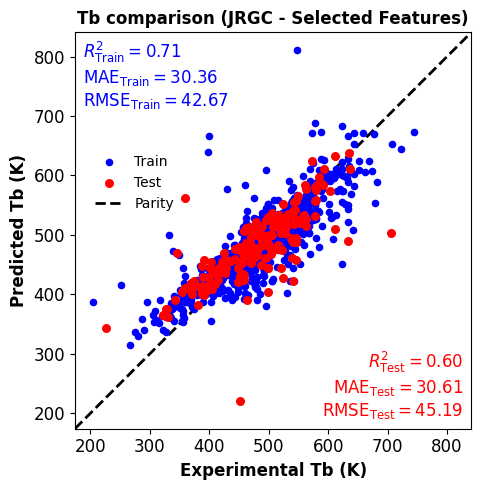

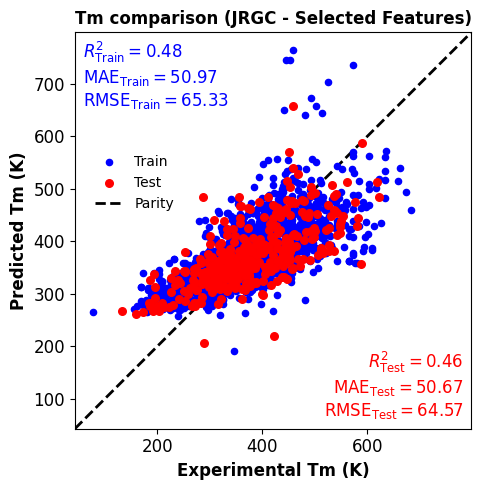

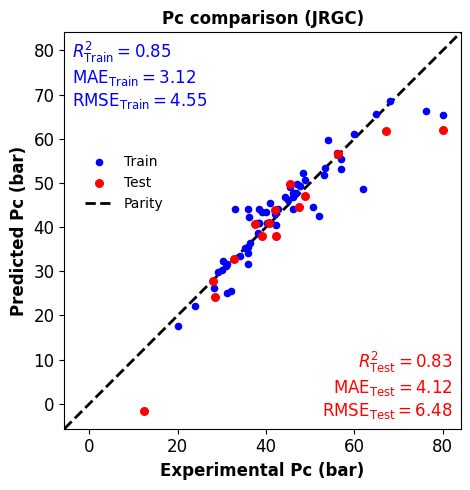

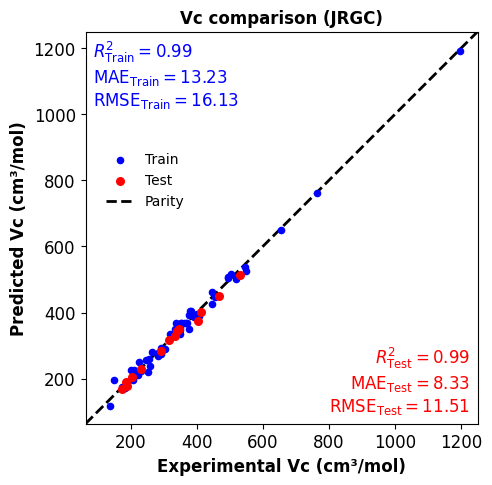

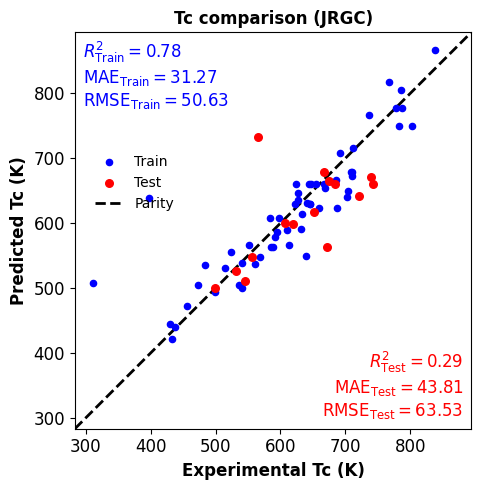

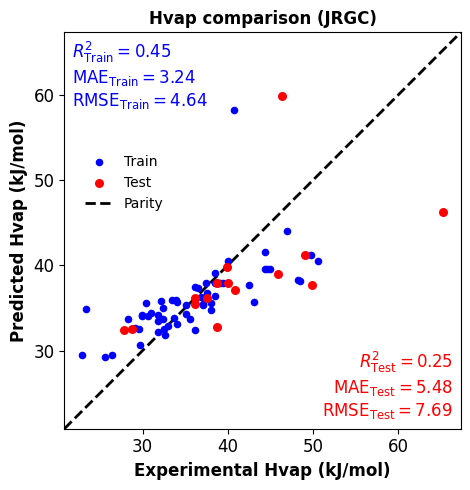

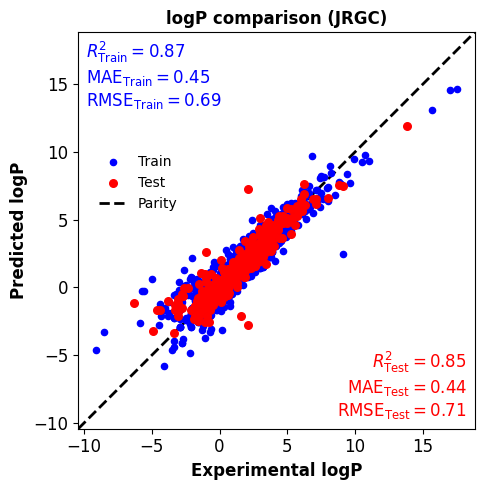

In [3]:
metricRows = []
coefficientTables = {}
for code in PROPERTY_ORDER:
    rows, coefficients = runBaseline(code, descriptorTable, outputDir)
    metricRows.extend(rows)
    coefficientTables[code] = coefficients

## 4. Results

### 4.1 Error metrics

The first row for each property is the fitted baseline shown in the figures
above, which is the reference for the GP models. The second row is the raw
GC estimate on exactly the same molecules, with no fitting, shown for context
only.

In [4]:
metricsDf = pd.DataFrame(metricRows)
metricsDf.to_csv(outputDir / "JRGC_statistical_metrics.csv", index=False)

metricsDf[["Property", "Model", "N_Train", "N_Test", "R2_Train", "R2_Test",
           "MAE_Test", "RMSE_Test", "MAPE_Test"]]

,Property,Model,N_Train,N_Test,R2_Train,R2_Test,MAE_Test,RMSE_Test,MAPE_Test
0,Tb,Linear GC baseline (fitted),771,193,0.707,0.604,30.613,45.186,6.746
1,Tb,Raw GC prediction,771,193,0.335,0.546,32.904,48.358,6.916
2,Tm,Linear GC baseline (fitted),1542,386,0.477,0.462,50.667,64.567,14.465
3,Tm,Raw GC prediction,1542,386,-1.908,-1.067,89.668,126.549,24.066
4,Pc,Linear GC baseline (fitted),58,15,0.855,0.831,4.119,6.479,13.703
5,Pc,Raw GC prediction,58,15,0.844,0.855,3.659,5.990,8.289
6,Vc,Linear GC baseline (fitted),55,14,0.991,0.989,8.335,11.509,2.449
7,Vc,Raw GC prediction,55,14,0.982,0.990,7.000,10.979,1.932
8,Tc,Linear GC baseline (fitted),58,15,0.782,0.289,43.808,63.532,6.781
9,Tc,Raw GC prediction,58,15,0.758,0.729,28.223,39.236,4.246


### 4.2 Where the linear correction helps

A positive number means the fitted baseline has a lower test RMSE than the raw
GC estimate.

In [5]:
pivot = metricsDf.pivot(index="Property", columns="Model", values="RMSE_Test").loc[PROPERTY_ORDER]
pivot["RMSE reduction from fitting"] = pivot["Raw GC prediction"] - pivot["Linear GC baseline (fitted)"]
pivot.round(2)

Model,Linear GC baseline (fitted),Raw GC prediction,RMSE reduction from fitting
Property,,,
Tb,45.19,48.36,3.17
Tm,64.57,126.55,61.98
Pc,6.48,5.99,-0.49
Vc,11.51,10.98,-0.53
Tc,63.53,39.24,-24.30
Hvap,7.69,10.59,2.91
logP,0.71,0.73,0.02


### 4.3 Fitted coefficients for Tb and Tm

Coefficients refer to standardized inputs, so their sizes can be compared
directly. A large coefficient on a topological index means that index adds
information the GC estimate is missing.

In [6]:
pd.concat({code: coefficientTables[code] for code in ["Tb", "Tm"]}, names=["Property", None])

Feature  Coefficient (standardized input)
Property                                               
Tb       0   Mol. wt.                            -9.204
         1     Wiener                           -31.054
         2  Zagreb_M1                            93.038
         3  Zagreb_M2                           -84.769
         4     Randic                            39.530
         5   JR Tb /K                            48.454
         6  Intercept                           488.223
Tm       0   Mol. wt.                           -25.840
         1     Wiener                           -21.165
         2  Zagreb_M1                           229.284
         3  Zagreb_M2                          -153.472
         4     Randic                           -74.169
         5   JR Tm /K                            85.649
         6  Intercept                           378.168

## 5. Summary of the results

The text below is written from the metrics computed above, so it always matches
the data of this run. It is also saved as
`Output_Data/jrgc_baseline/results_summary.md`.

In [7]:
from gcgp.narrative import describeBaseline, showAndSave

showAndSave(describeBaseline(metricsDf), outputDir / "results_summary.md");

## Group-contribution baseline: results

- **Tb** (771 training / 193 test molecules): the fitted baseline gives test R² = 0.604, MAE = 30.61 K and RMSE = 45.19 K. The raw GC estimate on the same test molecules has RMSE = 48.36 K (higher than the fitted baseline).
- **Tm** (1542 training / 386 test molecules): the fitted baseline gives test R² = 0.462, MAE = 50.67 K and RMSE = 64.57 K. The raw GC estimate on the same test molecules has RMSE = 126.5 K (higher than the fitted baseline).
- **Pc** (58 training / 15 test molecules): the fitted baseline gives test R² = 0.831, MAE = 4.12 bar and RMSE = 6.48 bar. The raw GC estimate on the same test molecules has RMSE = 5.99 bar (lower than the fitted baseline).
- **Vc** (55 training / 14 test molecules): the fitted baseline gives test R² = 0.989, MAE = 8.33 cm³/mol and RMSE = 11.51 cm³/mol. The raw GC estimate on the same test molecules has RMSE = 10.98 cm³/mol (lower than the fitted baseline).
- **Tc** (58 training / 15 test molecules): the fitted baseline gives test R² = 0.289, MAE = 43.81 K and RMSE = 63.53 K. The raw GC estimate on the same test molecules has RMSE = 39.24 K (lower than the fitted baseline).
- **ΔHvap** (60 training / 15 test molecules): the fitted baseline gives test R² = 0.246, MAE = 5.48 kJ/mol and RMSE = 7.69 kJ/mol. The raw GC estimate on the same test molecules has RMSE = 10.59 kJ/mol (higher than the fitted baseline).
- **log P** (2770 training / 693 test molecules): the fitted baseline gives test R² = 0.853, MAE = 0.444 and RMSE = 0.713. The raw GC estimate on the same test molecules has RMSE = 0.735 (higher than the fitted baseline).

For Pc, Vc, Tc, the raw GC estimate has a lower test RMSE than the fitted baseline.
